# Du Prétraitement à l'Évaluation et l'Interprétation d'un Modèle SVM sur le Titanic

Bienvenue dans ce notebook. Ce notebook regroupe dans un seul document l'intégralité du travail pratique en Python :
1. **Le prétraitement des données** : nettoyage, découpage stratifié, imputation des valeurs manquantes, correction de l'asymétrie, standardisation et encodage des catégories.
2. **La mise en place du modèle SVM** : définition des noyaux et recherche des meilleurs hyperparamètres par validation croisée (`GridSearchCV`).
3. **L'évaluation des performances** : mesure de la qualité du modèle sur le groupe de validation puis sur le jeu de test final (262 passagers).
4. **L'interprétation des résultats** : analyse des vecteurs de support, importance des variables explicatives et étude des passagers mal classés par le modèle.

## Pourquoi un algorithme SVM demande une préparation stricte ?
Un SVM (*Support Vector Machine* ou machine à vecteurs de support) est un algorithme géométrique. Il place chaque passager dans un espace mathématique et cherche la frontière qui sépare les survivants (`1`) des personnes décédées (`0`) avec la marge la plus large possible.
Pour calculer ces distances géométriques, le SVM a trois exigences :
* **Aucune case vide (`NaN`)** : un calcul de distance échoue s'il manque une valeur.
* **Uniquement des nombres** : le texte (`"male"`, `"female"`, `"S"`) doit être traduit en chiffres.
* **Des variables à la même échelle** : si le prix du billet va jusqu'à 512 et le sexe vaut 0 ou 1, le prix dominera tout le calcul de distance. Il faut donc standardiser les nombres.


## Étape 1 : Importation des bibliothèques et chargement des données brutes

Nous importons les outils de manipulation de données (`pandas`, `numpy`), de visualisation (`matplotlib`, `seaborn`) et de Machine Learning (`scikit-learn`).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder,
    FunctionTransformer
)
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    classification_report,
    confusion_matrix
)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)

# Chargement du fichier CSV initial
df = pd.read_csv("dataset/titanic.csv")

print(f"Dimensions initiales du dataset : {df.shape[0]} lignes et {df.shape[1]} colonnes.")
display(df.head(3))


Dimensions initiales du dataset : 1309 lignes et 15 colonnes.


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,boat,body,home.dest
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,NaN,NaN,"Bridgerule, Devon"
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,4,NaN,"New York, NY"
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,NaN,NaN,NaN


## Étape 2 : Sélection des variables explicatives ($X$) et de la cible ($y$)

Lors de l'analyse exploratoire (EDA) (voir notebook EDA), nous avons identifié plusieurs colonnes qu'il faut retirer avant d'entraîner le modèle :
* **`Survived`** : C'est la variable cible à prédire ($y$). On la retire de $X$ pour la mettre dans $y$.
* **`boat` et `body`** : Ce sont des fuites de données (*Data Leakage*). Le numéro du canot de sauvetage (`boat`) et le numéro du corps repêché (`body`) sont des informations connues après le naufrage. Les laisser reviendrait à tricher.
* **`PassengerId`** : C'est un simple numéro de ligne de 1 à 1309 sans valeur explicative.
* **`Name` et `Ticket`** : Ce sont des textes qui changent presque à chaque ligne (haute cardinalité).
* **`Cabin` et `home.dest`** : Ces colonnes contiennent beaucoup trop de valeurs manquantes (77,5 % pour `Cabin` et 43,1 % pour `home.dest`).

Nous conservons ainsi 7 variables explicatives pertinentes : `Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare` et `Embarked`.


In [2]:
colonnes_a_supprimer = [
    "Survived",
    "boat",
    "body",
    "PassengerId",
    "Name",
    "Ticket",
    "Cabin",
    "home.dest"
]

X_brut = df.drop(columns=colonnes_a_supprimer)
y_brut = df["Survived"]

print("Colonnes conservées dans X :", list(X_brut.columns))
print(f"Dimensions de X_brut : {X_brut.shape}")
print(f"Dimensions de y_brut : {y_brut.shape}")


Colonnes conservées dans X : ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
Dimensions de X_brut : (1309, 7)
Dimensions de y_brut : (1309,)


## Étape 3 : Découpage stratifié en Entraînement (80 %) et Test (20 %)

Avant de calculer la moindre médiane ou moyenne pour nettoyer les données, nous devons séparer notre jeu de données en deux :
* **L'ensemble d'entraînement (`X_train_brut`, `y_train`)** : 80 % des passagers (1 047 personnes). C'est sur ce groupe que l'on calcule les statistiques de nettoyage et que l'on entraîne le SVM.
* **L'ensemble de test (`X_test_brut`, `y_test`)** : 20 % des passagers (262 personnes). Ce groupe sert d'examen final. Il reste totalement isolé pendant les réglages.

L'option `stratify=y_brut` garantit que les deux groupes contiennent exactement la même proportion de survivants (38,2 %).


In [3]:
X_train_brut, X_test_brut, y_train, y_test = train_test_split(
    X_brut,
    y_brut,
    test_size=0.2,
    random_state=42,
    stratify=y_brut
)

print(f"Ensemble d'entraînement : {X_train_brut.shape[0]} passagers (taux de survie : {y_train.mean() * 100:.2f} %)")
print(f"Ensemble de test        : {X_test_brut.shape[0]} passagers (taux de survie : {y_test.mean() * 100:.2f} %)")


Ensemble d'entraînement : 1047 passagers (taux de survie : 38.20 %)
Ensemble de test        : 262 passagers (taux de survie : 38.17 %)


## Étape 4 : Construction du pipeline de prétraitement (`ColumnTransformer`)

Chaque groupe de colonnes reçoit un traitement adapté à sa nature :
1. **Variables numériques standards (`Age`, `SibSp`, `Parch`)** :
   * Remplacement des valeurs manquantes par la **médiane** (`SimpleImputer(strategy="median")`).
   * **Standardisation** (`StandardScaler()`) pour ramener la moyenne à 0 et l'écart-type à 1.
2. **Variable `Fare` (Prix du billet)** :
   * Remplacement de la valeur manquante par la **médiane**.
   * Transformation logarithmique `np.log1p` ($\ln(1 + x)$) pour corriger la forte asymétrie des prix (quelques billets très chers jusqu'à 512 livres).
   * **Standardisation** (`StandardScaler()`).
3. **Variable binaire `Sex`** :
   * Remplacement d'éventuelles valeurs manquantes par la valeur la plus fréquente.
   * Encodage binaire (`OrdinalEncoder`) : `male` devient `0.0` et `female` devient `1.0`.
4. **Variables catégorielles à 3 modalités (`Pclass`, `Embarked`)** :
   * Remplacement des valeurs manquantes par la modalité la plus fréquente (`S` pour `Embarked`).
   * Encodage **One-Hot** (`OneHotEncoder(drop="first")`) qui crée des colonnes binaires `0` ou `1` en omettant la première catégorie de référence pour éviter la redondance.


In [4]:
# 1. Pipeline pour Age, SibSp et Parch
colonnes_numeriques_normales = ["Age", "SibSp", "Parch"]
pipeline_numerique = Pipeline([
    ("imputation", SimpleImputer(strategy="median")),
    ("standardisation", StandardScaler())
])

# 2. Pipeline pour Fare
colonne_fare = ["Fare"]
pipeline_fare = Pipeline([
    ("imputation", SimpleImputer(strategy="median")),
    ("logarithme", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("standardisation", StandardScaler())
])

# 3. Pipeline pour Sex
colonne_sexe = ["Sex"]
pipeline_sexe = Pipeline([
    ("imputation", SimpleImputer(strategy="most_frequent")),
    ("encodage", OrdinalEncoder(categories=[["male", "female"]]))
])

# 4. Pipeline pour Pclass et Embarked
colonnes_categorielles = ["Pclass", "Embarked"]
pipeline_categoriel = Pipeline([
    ("imputation", SimpleImputer(strategy="most_frequent")),
    ("encodage", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))
])

# Assemblage des 4 branches
pretraitement = ColumnTransformer(
    transformers=[
        ("numerique", pipeline_numerique, colonnes_numeriques_normales),
        ("fare", pipeline_fare, colonne_fare),
        ("sexe", pipeline_sexe, colonne_sexe),
        ("categoriel", pipeline_categoriel, colonnes_categorielles)
    ]
)

pipeline_pretraitement = Pipeline([
    ("pretraitement", pretraitement)
])

# Application : fit_transform sur l'entraînement, transform sur le test
X_train_prepare = pipeline_pretraitement.fit_transform(X_train_brut)
X_test_prepare = pipeline_pretraitement.transform(X_test_brut)

noms_colonnes_finales = pipeline_pretraitement.named_steps["pretraitement"].get_feature_names_out()

X_train = pd.DataFrame(X_train_prepare, columns=noms_colonnes_finales)
X_test = pd.DataFrame(X_test_prepare, columns=noms_colonnes_finales)

# Sauvegarde des fichiers CSV préparés
train_final_df = X_train.copy()
train_final_df["Survived"] = y_train.values
test_final_df = X_test.copy()
test_final_df["Survived"] = y_test.values

train_final_df.to_csv("dataset/train.csv", index=False)
test_final_df.to_csv("dataset/test.csv", index=False)

print(f"Tableau d'entraînement préparé : {X_train.shape[0]} lignes et {X_train.shape[1]} colonnes.")
print(f"Tableau de test préparé        : {X_test.shape[0]} lignes et {X_test.shape[1]} colonnes.")
display(X_train.head(5))


Tableau d'entraînement préparé : 1047 lignes et 9 colonnes.
Tableau de test préparé        : 262 lignes et 9 colonnes.


,numerique__Age,numerique__SibSp,numerique__Parch,fare__Fare,sexe__Sex,categoriel__Pclass_2,categoriel__Pclass_3,categoriel__Embarked_Q,categoriel__Embarked_S
0,-0.112493,-0.475419,-0.429878,0.334962,0.0,0.0,0.0,0.0,0.0
1,-0.889279,-0.475419,1.831843,1.460834,1.0,0.0,0.0,0.0,1.0
2,-0.656243,-0.475419,-0.429878,-0.864462,0.0,0.0,1.0,0.0,1.0
3,2.683936,0.538356,-0.429878,1.403615,0.0,0.0,0.0,0.0,0.0
4,-2.223020,0.538356,0.700982,0.025858,0.0,1.0,0.0,0.0,1.0


## Étape 5 : Mise en place du modèle SVM et optimisation des hyperparamètres

Pour régler notre SVM sans toucher au jeu de test final (262 passagers), nous divisons nos 1 047 passagers d'entraînement en deux sous-groupes :
* **Un sous-ensemble d'entraînement interne (837 passagers)** sur lequel nous lançons une recherche par grille avec validation croisée à 5 plis (`GridSearchCV` + `StratifiedKFold`).
* **Un sous-ensemble de validation (210 passagers)** pour contrôler la performance du meilleur réglage avant le réentraînement complet.

### Quels hyperparamètres testons-nous dans la grille ?
Nous comparons **42 configurations** réparties sur trois familles de noyaux :
1. **Noyau linéaire (`linear`)** : cherche une frontière plate (4 valeurs de $C$ : `0.1, 1, 10, 100`).
2. **Noyau radial gaussien (`rbf`)** : cherche une frontière courbe souple (4 valeurs de $C$ croisées avec 5 valeurs de $\gamma$ : `'scale', 'auto', 0.01, 0.1, 1`, soit 20 combinaisons).
3. **Noyau polynomial (`poly`)** : cherche une frontière polynomiale (3 valeurs de $C$, 3 degrés `2, 3, 4` et 2 valeurs de $\gamma$, soit 18 combinaisons).

La métrique choisie pour classer les modèles est le **F1-score**, car il équilibre la **Précision** (ne pas prédire survivant à tort) et le **Rappel** (ne pas oublier de vrais survivants).


In [5]:
# Séparation interne : 837 pour l'entraînement local et 210 pour la validation
X_train_local, X_val, y_train_local, y_val = train_test_split(
    X_train,
    y_train.reset_index(drop=True),
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

pipeline_svm = Pipeline([
    ("classificateur", SVC())
])

parametres = [
    {
        "classificateur__kernel": ["linear"],
        "classificateur__C": [0.1, 1, 10, 100]
    },
    {
        "classificateur__kernel": ["rbf"],
        "classificateur__C": [0.1, 1, 10, 100],
        "classificateur__gamma": ["scale", "auto", 0.01, 0.1, 1]
    },
    {
        "classificateur__kernel": ["poly"],
        "classificateur__C": [0.1, 1, 10],
        "classificateur__degree": [2, 3, 4],
        "classificateur__gamma": ["scale", "auto"]
    }
]

validation_croisee = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

recherche = GridSearchCV(
    estimator=pipeline_svm,
    param_grid=parametres,
    scoring="f1",
    cv=validation_croisee,
    n_jobs=-1,
    verbose=1
)

recherche.fit(X_train_local, y_train_local)

print("Meilleurs hyperparamètres retenus :", recherche.best_params_)
print(f"Meilleur F1-score moyen en validation croisée : {recherche.best_score_:.4f}")


Fitting 5 folds for each of 42 candidates, totalling 210 fits


Meilleurs hyperparamètres retenus : {'classificateur__C': 100, 'classificateur__gamma': 0.01, 'classificateur__kernel': 'rbf'}
Meilleur F1-score moyen en validation croisée : 0.7273


### Comparaison des performances selon le type de noyau

Regardons dans les résultats de `GridSearchCV` quel est le meilleur score F1 atteint par chacun des trois noyaux testés (`linear`, `poly`, `rbf`).


In [6]:
resultats_cv = pd.DataFrame(recherche.cv_results_)
meilleurs_par_noyau = (
    resultats_cv.groupby("param_classificateur__kernel")["mean_test_score"]
    .max()
    .reset_index()
    .rename(columns={
        "param_classificateur__kernel": "Noyau (kernel)",
        "mean_test_score": "Meilleur F1-score (Validation Croisée)"
    })
    .sort_values(by="Meilleur F1-score (Validation Croisée)", ascending=False)
)
display(meilleurs_par_noyau.round(4))


,Noyau (kernel),Meilleur F1-score (Validation Croisée)
2,rbf,0.7273
1,poly,0.7194
0,linear,0.6966


## Étape 6 : Évaluation sur la Validation (210 passagers) puis sur le Test final (262 passagers)

Maintenant que la configuration optimale est identifiée (`kernel='rbf'`, `C=100`, `gamma=0.01`), nous procédons en deux temps :
1. Nous vérifions sa performance sur les **210 passagers de validation**.
2. Nous **réentraînons ce meilleur modèle sur la totalité des 1 047 passagers d'entraînement** afin qu'il profite de toute l'information disponible, puis nous l'évaluons une seule fois sur les **262 passagers du jeu de test final**.


In [7]:
# 1. Évaluation sur le sous-ensemble de validation (210 passagers)
meilleur_modele = recherche.best_estimator_
y_val_pred = meilleur_modele.predict(X_val)

# 2. Réentraînement sur l'ensemble des 1047 passagers d'entraînement
y_train_reset = y_train.reset_index(drop=True)
y_test_reset = y_test.reset_index(drop=True)
meilleur_modele.fit(X_train, y_train_reset)

# 3. Prédictions sur les 262 passagers du jeu de test
y_test_pred = meilleur_modele.predict(X_test)
y_test_scores = meilleur_modele.decision_function(X_test)

# Tableau comparatif Validation vs Test
bilan_metriques = pd.DataFrame({
    "Validation (210 passagers)": [
        accuracy_score(y_val, y_val_pred) * 100,
        precision_score(y_val, y_val_pred) * 100,
        recall_score(y_val, y_val_pred) * 100,
        f1_score(y_val, y_val_pred) * 100,
        np.nan
    ],
    "Test Final (262 passagers)": [
        accuracy_score(y_test_reset, y_test_pred) * 100,
        precision_score(y_test_reset, y_test_pred) * 100,
        recall_score(y_test_reset, y_test_pred) * 100,
        f1_score(y_test_reset, y_test_pred) * 100,
        roc_auc_score(y_test_reset, y_test_scores) * 100
    ]
}, index=["Accuracy (%)", "Précision (%)", "Rappel / Recall (%)", "F1-score (%)", "ROC-AUC (%)"])

display(bilan_metriques.round(2))

print("\nRapport de classification complet sur le jeu de test (262 passagers) :")
print(classification_report(y_test_reset, y_test_pred))


,Validation (210 passagers),Test Final (262 passagers)
Accuracy (%),80.95,81.30
Précision (%),77.78,78.65
Rappel / Recall (%),70.00,70.00
F1-score (%),73.68,74.07
ROC-AUC (%),NaN,83.94



Rapport de classification complet sur le jeu de test (262 passagers) :
              precision    recall  f1-score   support

           0       0.83      0.88      0.85       162
           1       0.79      0.70      0.74       100

    accuracy                           0.81       262
   macro avg       0.81      0.79      0.80       262
weighted avg       0.81      0.81      0.81       262



### Visualisation graphique : Matrice de confusion et Courbe ROC sur le jeu de test

Pour évaluer visuellement notre modèle :
* **La matrice de confusion** croise la vraie classe du passager (en ligne) et la prédiction du SVM (en colonne).
* **La courbe ROC** montre la capacité du SVM à séparer les survivants des personnes décédées pour tous les seuils de décision possibles. Plus l'aire sous la courbe (**AUC**) est proche de 1 (ici **0,8394**), meilleur est le pouvoir discriminant du modèle.


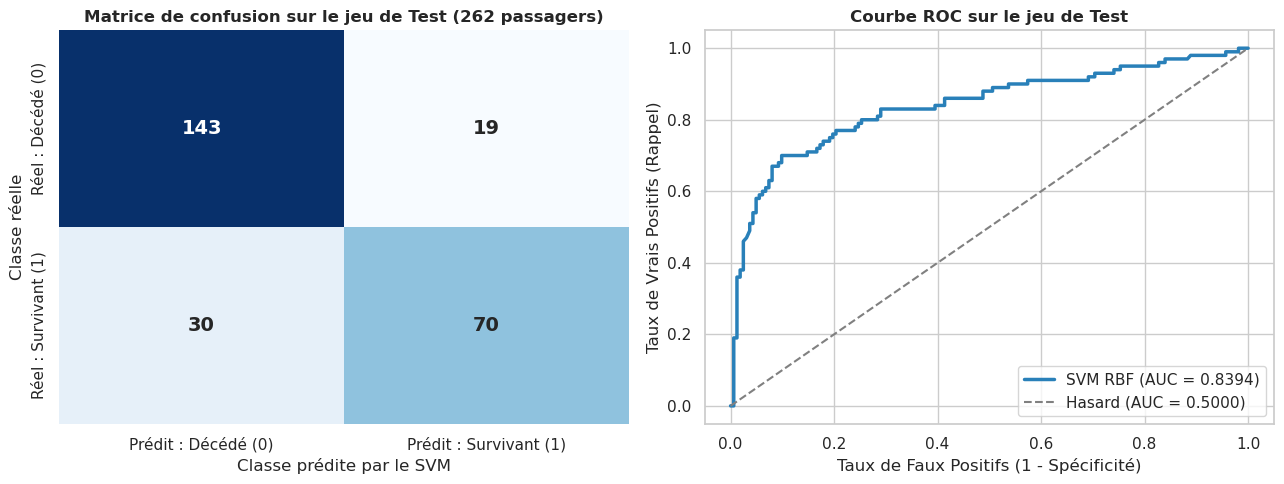

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Graphique 1 : Matrice de confusion sur le jeu de test
matrice_test = confusion_matrix(y_test_reset, y_test_pred)
sns.heatmap(
    matrice_test,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Prédit : Décédé (0)", "Prédit : Survivant (1)"],
    yticklabels=["Réel : Décédé (0)", "Réel : Survivant (1)"],
    cbar=False,
    annot_kws={"size": 14, "weight": "bold"},
    ax=axes[0]
)
axes[0].set_title("Matrice de confusion sur le jeu de Test (262 passagers)", fontweight="bold")
axes[0].set_ylabel("Classe réelle")
axes[0].set_xlabel("Classe prédite par le SVM")

# Graphique 2 : Courbe ROC
fpr, tpr, _ = roc_curve(y_test_reset, y_test_scores)
auc_val = roc_auc_score(y_test_reset, y_test_scores)
axes[1].plot(fpr, tpr, color="#2980b9", lw=2.5, label=f"SVM RBF (AUC = {auc_val:.4f})")
axes[1].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Hasard (AUC = 0.5000)")
axes[1].set_title("Courbe ROC sur le jeu de Test", fontweight="bold")
axes[1].set_xlabel("Taux de Faux Positifs (1 - Spécificité)")
axes[1].set_ylabel("Taux de Vrais Positifs (Rappel)")
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


## Étape 7 : Interprétation approfondie des résultats

Un bon Data Scientist ne s'arrête pas aux pourcentages (je ne dis pas que je suis déjà expert). Il cherche à comprendre **comment** le modèle prend ses décisions et **sur quels passagers** il se trompe.

### 7.1. Pourquoi la combinaison `kernel='rbf'`, `C=100` et `gamma=0.01` a-t-elle gagné ?
* **Le noyau `rbf` combiné à un petit `gamma` (`0.01`)** : Dans un noyau RBF, un `gamma` très faible donne une frontière courbe très douce et régulière. Cela permet au SVM de capturer les interactions non linéaires majeures (par exemple, le fait qu'une femme de 1ère ou 2ème classe survit à plus de 90 %, alors qu'en 3ème classe son taux de survie tombe à 49 %) sans créer de petits îlots de surapprentissage autour des passagers isolés.
* **Le paramètre `C=100` compense la douceur de `gamma=0.01`** : Comme `gamma=0.01` lisse fortement la frontière, un `C` élevé (`100`) pénalise davantage les erreurs de classement et force cette frontière lisse à bien se placer entre les groupes.
* **Stabilité remarquable entre Validation et Test** : Le F1-score passe de **73,68 %** en validation à **74,07 %** sur le test final, et l'Accuracy passe de **80,95 %** à **81,30 %**. Comme le score de test ne chute pas par rapport à la validation, **il n'y a pas de surapprentissage**.

### 7.2. Analyse des vecteurs de support et de l'importance des variables
Avec un noyau non linéaire comme `rbf`, le SVM ne fournit pas un simple coefficient par colonne. Pour mesurer le poids de chaque variable dans les décisions du SVM, on utilise **l'importance par permutation** (*Permutation Importance*) : on mélange au hasard une colonne à la fois sur le jeu de test et on mesure de combien le F1-score chute. Plus le score chute, plus cette variable était essentielle au modèle !


Nombre total de vecteurs de support : 455 sur 1047 passagers d'entraînement (43.5 %)
 - Classe 0 (Décédés)    : 234 vecteurs de support
 - Classe 1 (Survivants) : 221 vecteurs de support


,Variable,Baisse moyenne du F1-score,Écart-type
4,sexe__Sex,0.3327,0.0361
1,numerique__SibSp,0.0305,0.0081
6,categoriel__Pclass_3,0.0273,0.0081
0,numerique__Age,0.0198,0.0062
2,numerique__Parch,0.0063,0.0054
8,categoriel__Embarked_S,0.0023,0.0042
5,categoriel__Pclass_2,0.0019,0.0026
7,categoriel__Embarked_Q,-0.0003,0.0025
3,fare__Fare,-0.0035,0.0012


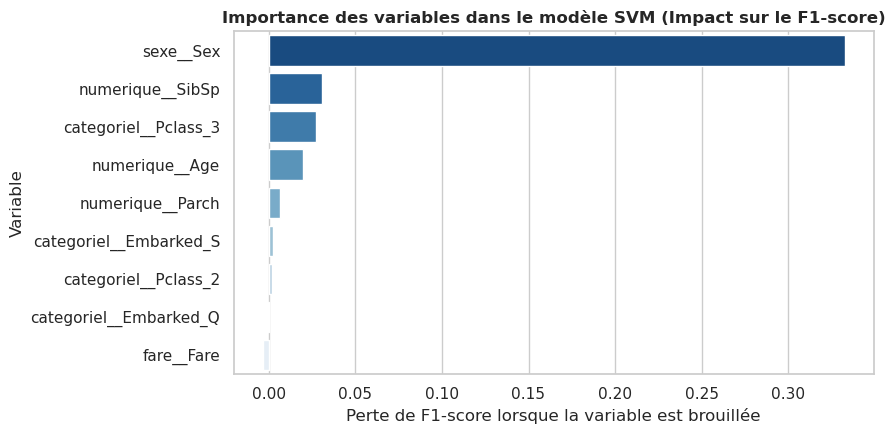

In [9]:
modele_svc = meilleur_modele.named_steps["classificateur"]
nb_supports = modele_svc.n_support_

print(f"Nombre total de vecteurs de support : {nb_supports.sum()} sur {len(X_train)} passagers d'entraînement ({nb_supports.sum() / len(X_train) * 100:.1f} %)")
print(f" - Classe 0 (Décédés)    : {nb_supports[0]} vecteurs de support")
print(f" - Classe 1 (Survivants) : {nb_supports[1]} vecteurs de support")

# Calcul de l'importance des variables par permutation
importance = permutation_importance(
    meilleur_modele,
    X_test,
    y_test_reset,
    scoring="f1",
    n_repeats=20,
    random_state=42
)

df_imp = pd.DataFrame({
    "Variable": X_test.columns,
    "Baisse moyenne du F1-score": importance.importances_mean,
    "Écart-type": importance.importances_std
}).sort_values(by="Baisse moyenne du F1-score", ascending=False)

display(df_imp.round(4))

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(
    data=df_imp,
    x="Baisse moyenne du F1-score",
    y="Variable",
    hue="Variable",
    palette="Blues_r",
    legend=False,
    ax=ax
)
ax.set_title("Importance des variables dans le modèle SVM (Impact sur le F1-score)", fontweight="bold")
ax.set_xlabel("Perte de F1-score lorsque la variable est brouillée")
plt.tight_layout()
plt.show()


### 7.3. Analyse métier des erreurs de classification sur les 262 passagers du Test

Sur les 262 passagers du jeu de test :
* **213 passagers sont correctement classés (81,30 %)** : 143 vrais négatifs (décédés bien prédits) et 70 vrais positifs (survivants bien prédits).
* **49 passagers sont mal classés (18,70 %)** :
  * **19 Faux Positifs** : passagers décédés que le SVM avait prédits comme survivants.
  * **30 Faux Négatifs** : passagers survivants que le SVM avait prédits comme décédés.

Regardons le profil réel (avant standardisation) de ces 49 passagers pour comprendre pourquoi le SVM s'est trompé sur eux :


In [10]:
# Reconstruction d'un tableau lisible avec les caractéristiques d'origine des 262 passagers du test
analyse_test = X_test_brut.copy()
analyse_test["Reel_Survived"] = y_test.values
analyse_test["Predit_Survived"] = y_test_pred

faux_positifs = analyse_test[(analyse_test["Reel_Survived"] == 0) & (analyse_test["Predit_Survived"] == 1)]
faux_negatifs = analyse_test[(analyse_test["Reel_Survived"] == 1) & (analyse_test["Predit_Survived"] == 0)]

print(f"1. Profil des {len(faux_positifs)} Faux Positifs (Prédits survivants mais en réalité décédés) :")
print(faux_positifs.groupby(["Sex", "Pclass"]).size().rename("Nombre de passagers"))

print(f"\n2. Profil des {len(faux_negatifs)} Faux Négatifs (Prédits décédés mais en réalité survivants) :")
print(faux_negatifs.groupby(["Sex", "Pclass"]).size().rename("Nombre de passagers"))


1. Profil des 19 Faux Positifs (Prédits survivants mais en réalité décédés) :
Sex     Pclass
female  1          2
        2          1
        3         15
male    1          1
Name: Nombre de passagers, dtype: int64

2. Profil des 30 Faux Négatifs (Prédits décédés mais en réalité survivants) :
Sex     Pclass
female  3          1
male    1         13
        2          3
        3         13
Name: Nombre de passagers, dtype: int64


### 7.4. Bilan de l'analyse des erreurs

Les chiffres ci-dessus expliquent très clairement le comportement du SVM :
1. **Pourquoi cette importance dominante de `sexe__Sex`, `numerique__SibSp`, `categoriel__Pclass_3` et `numerique__Age` ?**
   * Le graphique d'importance montre que **le sexe (`sexe__Sex`) est de loin le pilier n°1 du modèle** : si on brouille le sexe, le F1-score s'effondre de **0,33 point**. Viennent ensuite la taille de la fratrie/conjoint (`numerique__SibSp`), le fait d'être en 3ème classe (`categoriel__Pclass_3`) et l'âge (`numerique__Age`).
2. **Qui sont les 19 Faux Positifs (prédits survivants à tort) ?**
   * Ce sont **exclusivement des femmes** (dont 16 femmes de 3ème classe). Comme les femmes survivent en moyenne à 72,7 %, le SVM prédit leur survie, mais en 3ème classe la moitié des femmes n'a pas pu atteindre les canots.
3. **Qui sont les 30 Faux Négatifs (survivants non détectés par le modèle, ce qui explique le Rappel de 70 %) ?**
   * Ce sont en grande majorité **des hommes adultes** (22 hommes répartis dans les 3 classes, plus 8 femmes de 3ème classe) qui ont réussi à survivre malgré un taux de survie masculin très bas (19,1 %). Sans variable supplémentaire indiquant leur emplacement exact au moment de l'impact ou leur titre social, aucun modèle statistique ne peut deviner lesquels des hommes adultes ont pu monter dans un canot.
